# Strip waveguide S-bend 
This notebook contains code that simulates bend waveguide parameters using **Tidy3d**. \
The objective is to obtain loss values across radius sweep.

https://www.flexcompute.com/tidy3d/examples/notebooks/SbendCMAES

In [1]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

# Import modules
from datetime import datetime
import cma
from IPython.display import display
import lumapi as lma
import math
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [2]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [3]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [4]:
# Si3N4/SiO2 1000x360nm 1550nm
experiment_name = "si3n4_w1000nm_h360nm_sbend_w4um_l4um"
wavelength_center = 1.55*um
wavelength_span = 0.30*um

sbend_length = 15*um
sbend_width = 5*um

core_thickness = 360*nm
core_width = 1000*nm
bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [40]:
# Si/SiO2 430x220nm 1550nm
experiment_name = "si_w430nm_h220nm_sbend_w4um_l4um"
wavelength_center = 1.55*um
wavelength_span = 0.30*um

sbend_length = 4*um
sbend_width = 4*um

core_thickness = 220*nm
core_width = 430*nm
bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si (Silicon) - Palik"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [41]:
# Pre-calculate parameters for solver

field_intensity_log_decay = -6

ports_offset = sbend_length/20
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

initial_fdtd_height = initial_ports_height + 2*wavelength_center
initial_fdtd_length = sbend_length + 2*ports_offset + 2*wavelength_center
initial_fdtd_width = sbend_width + initial_ports_width + 2*wavelength_center

In [7]:
# Get solver
solver = lma.FDTD(hide=False)

In [42]:
# Helper for safe removal

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

# Materials

In [43]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

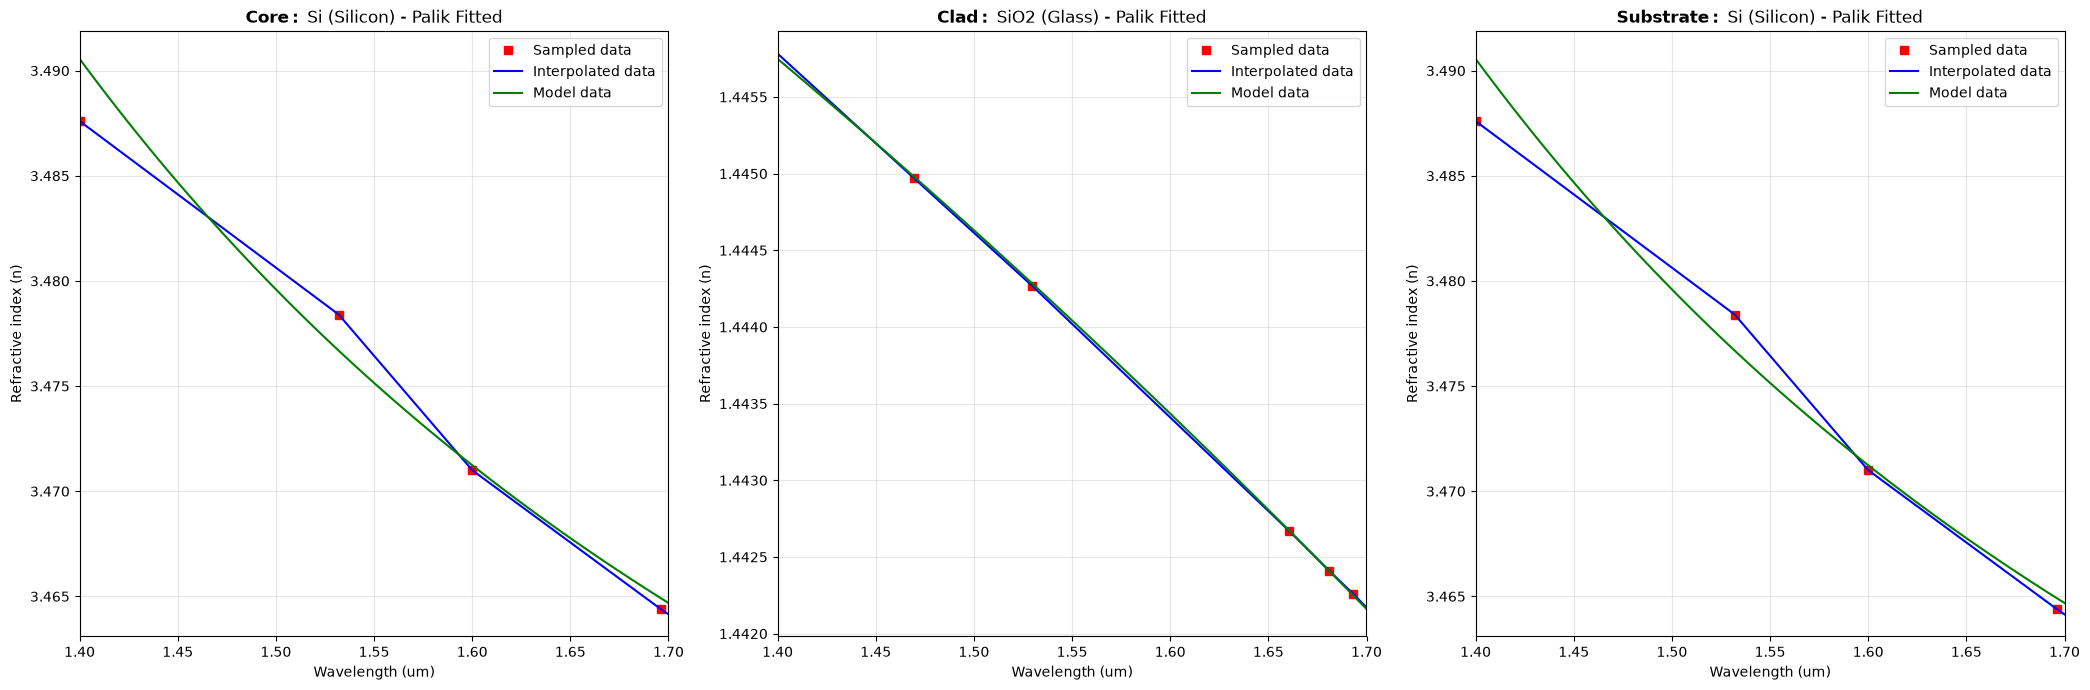

In [44]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

In [45]:
# Structure geometry

clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness

def bezier_curve(control_points, num_points=100):
    t = np.linspace(0, 1, num_points)
    curve = np.zeros((num_points, 2))
    n = len(control_points) - 1  # degree of the Bézier curve

    for i in range(n + 1):
        binomial_coeff = math.factorial(n) / (math.factorial(i) * math.factorial(n - i))
        term = binomial_coeff * (1 - t) ** (n - i) * t**i
        curve += np.outer(term, control_points[i])

    return curve

def make_sbend(v):
    p_input = np.array([-sbend_length/2, -sbend_width/2 - core_width/2])
    p_output = np.array([sbend_length/2, sbend_width/2 - core_width/2])

    sbend_bot_points = np.array(
        [
            p_input,
            [v[0], v[1]],
            [v[2], v[3]],
            [v[4], 0],
            [v[5], v[6]],
            [v[7], v[8]],
            p_output,
        ]
    )

    sbend_bot_curve = bezier_curve(sbend_bot_points)
    sbend_top_curve = -sbend_bot_curve
    vertices = np.vstack((sbend_bot_curve, sbend_top_curve))

    solver.addpoly(
        name="s-bend",
        vertices=vertices,
        z_min=-core_thickness/2,
        z_max=core_thickness/2,
        material=core_material,
    )

# Substrate
remove("substrate")
solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=100*um,
    material=substrate_material,
    alpha=0.8,
)

# Clad
remove("clad")
solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=100*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

# S-bend
p1 = np.array([-sbend_length/4 - core_width/4, -sbend_width/2 - core_width/2])
p2 = np.array([core_width/2, -sbend_width/4 - core_width/4])
p3 = np.array([core_width/2, 0])
p4 = np.array([core_width/2, sbend_width/4 - core_width/4])
p5 = np.array([sbend_length/4 - core_width/4, sbend_width/2 - core_width/2])

sbend_initial_v = np.array([
    p1[0], p1[1],
    p2[0], p2[1],
    p3[0],
    p4[0], p4[1],
    p5[0], p5[1]
])

remove("s-bend")
make_sbend(sbend_initial_v)

# Input waveguide
remove("waveguide-in")
solver.addrect(
    name="waveguide-in",
    x_min=-100*um, x_max=-sbend_length/2,
    y=-sbend_width/2, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

# Output waveguide
remove("waveguide-out")
solver.addrect(
    name="waveguide-out",
    x_min=sbend_length/2, x_max=100*um,
    y=sbend_width/2, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

In [61]:
# Simulation setup

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
    z_span=initial_fdtd_height,
)

solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Input
remove("port-in")
solver.addport(
    name="port-in",
    injection_axis="x-axis",
    x=-sbend_length/2 - ports_offset, 
    y=-sbend_width/2, 
    z=0,
    y_span=initial_ports_width, 
    z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Output
remove("port-out")
solver.addport(
    name="port-out",
    injection_axis="x-axis",
    x=sbend_length/2 + ports_offset, 
    y=sbend_width/2, 
    z=0,
    y_span=initial_ports_width, 
    z_span=initial_ports_height,
    direction="Backward",
);

solver.setnamed("FDTD::ports", "monitor frequency points", 101)


# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 3)

In [ ]:
# Simulation preview
sim = make_sim(sbend_initial_v, include_fmonitor = True)
sim.plot_3d()

# Cost estimate
job = td.web.Job(
    simulation=sim,
    task_name="S-bend initial simulation"
)

estimated_cost = job.estimate_cost()
print(f"Estimated cost for initial simulation: {estimated_cost:.3f} FlexCredits")

In [ ]:
# Initial simulation

sim_data = td.web.run(sim, task_name="S-bend initial simulation")

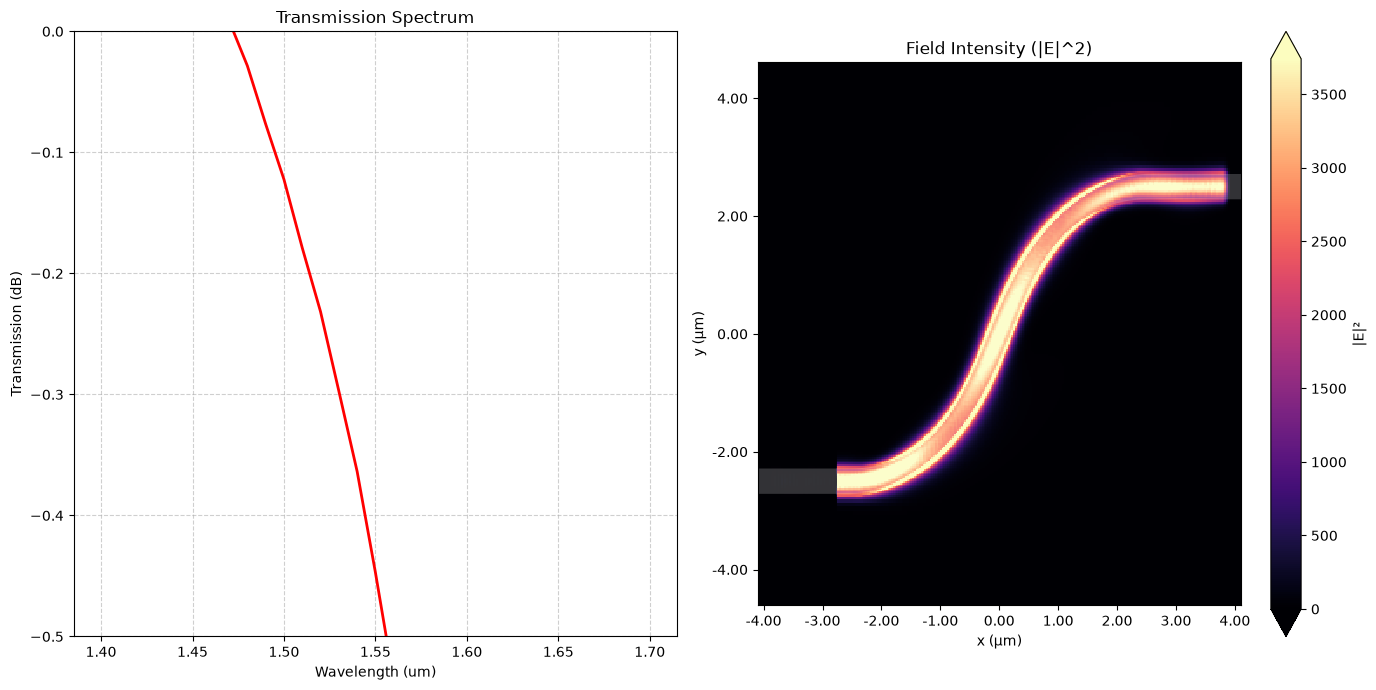

In [47]:
def compute_transmission(sim_data):
    amps = sim_data["mode"].amps.sel(mode_index=0, direction="+").values
    return np.abs(amps) ** 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

T_opt = 10 * np.log10(compute_transmission(sim_data))
ax1.plot(wavelengths * 1e6, T_opt, "red", linewidth=2)
ax1.set_ylim(-0.5, 0)
ax1.set_ylabel("Transmission (dB)")
ax1.set_xlabel("Wavelength (um)")
ax1.set_title("Transmission Spectrum")
ax1.grid(True, linestyle="--", alpha=0.6)

sim_data.plot_field(
    field_monitor_name="field", 
    field_name="E", 
    val="abs^2",
    f=frequency_center,
    ax=ax2,
)
ax2.set_title("Field Intensity (|E|^2)")

plt.tight_layout()
plt.show()

# Optimization

In [ ]:
def objective_function(xs):
    sims = {}
    for i, x in enumerate(xs):
        sim = make_sim(x)
        sims[f"population_{i}"] = sim

    batch = web.Batch(simulations=sims, verbose=False)
    batch_results = batch.run(path_dir="data")

    T = []
    for i, _ in enumerate(xs):
        sim_data = batch_results[f"population_{i}"]
        T.append(-10 * np.log10(np.mean(compute_transmission(sim_data))))
    return T

In [ ]:
dim = len(x0)
population_size = 10
max_generations = 12
sigma0 = 0.05
random_seed = 12345

es = cma.CMAEvolutionStrategy(
    x0, sigma0, {"popsize": population_size, "maxiter": max_generations, "seed": random_seed}
)

In [ ]:
best_values = []

generation = 0
while not es.stop():
    solutions = es.ask()
    function_values = objective_function(solutions)
    es.tell(solutions, function_values)

    best_values.append(es.result[1])

    # Print message for each generation
    print(f"Generation {generation}: Best function value = {es.result[1]:.3f}")

    generation += 1